### Setup for the Project 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report , confusion_matrix , roc_auc_score , recall_score , precision_score , f1_score
from sklearn.model_selection import GridSearchCV , StratifiedKFold
from sklearn.ensemble import AdaBoostClassifier
from lightgbm import LGBMClassifier
import numpy as np
from sklearn.model_selection import cross_val_predict
import joblib
import time

### importing Dataset 

In [2]:
df = pd.read_csv("bank-additional-full.csv", sep=";")
df.shape
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Data Preparation

In [3]:
df = df.drop(columns = "duration")

In [4]:
df["y"] = df["y"].map({"no": 0, "yes": 1})

In [5]:
df["y"]

0        0
1        0
2        0
3        0
4        0
        ..
41183    1
41184    0
41185    0
41186    1
41187    0
Name: y, Length: 41188, dtype: int64

### Performing EDA on Dataset

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 20 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  campaign        41188 non-null  int64  
 11  pdays           41188 non-null  int64  
 12  previous        41188 non-null  int64  
 13  poutcome        41188 non-null  str    
 14  emp.var.rate    41188 non-null  float64
 15  cons.price.idx  41188 non-null  float64
 16  cons.conf.idx   41188 non-null  float64
 17  euribor3m       41188 non-null  float64
 1

In [7]:
print(df.isnull().sum)
print("Duplicates:", df.duplicated().sum)

<bound method DataFrame.sum of          age    job  marital  education  default  housing   loan  contact  \
0      False  False    False      False    False    False  False    False   
1      False  False    False      False    False    False  False    False   
2      False  False    False      False    False    False  False    False   
3      False  False    False      False    False    False  False    False   
4      False  False    False      False    False    False  False    False   
...      ...    ...      ...        ...      ...      ...    ...      ...   
41183  False  False    False      False    False    False  False    False   
41184  False  False    False      False    False    False  False    False   
41185  False  False    False      False    False    False  False    False   
41186  False  False    False      False    False    False  False    False   
41187  False  False    False      False    False    False  False    False   

       month  day_of_week  campaign  pdays  

In [8]:
cat_cols = df.select_dtypes(include="str").columns
for col in cat_cols:
   print(col, (df[col] == "unknown").sum())

job 330
marital 80
education 1731
default 8597
housing 990
loan 990
contact 0
month 0
day_of_week 0
poutcome 0


In [9]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True)*100)


y
0    36548
1     4640
Name: count, dtype: int64
y
0    88.734583
1    11.265417
Name: proportion, dtype: float64


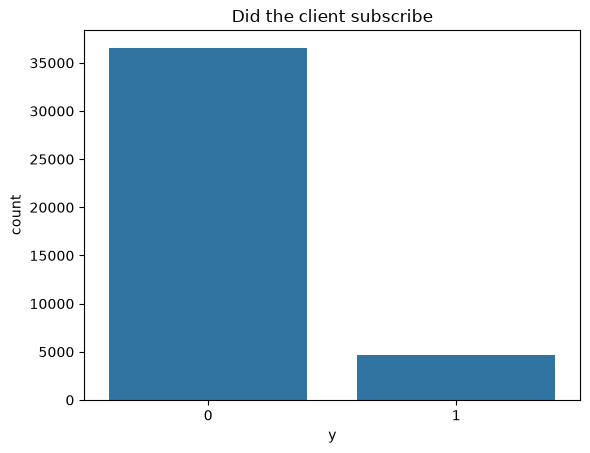

In [10]:
sns.countplot(x="y",data=df)
plt.title("Did the client subscribe")
plt.show()

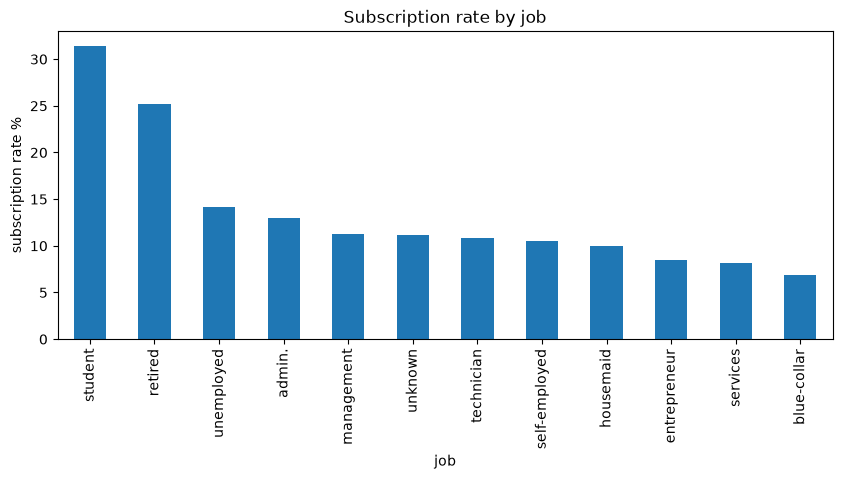

In [11]:
job_rate = df.groupby("job")["y"].mean().sort_values(ascending=False)*100
job_rate.plot(kind="bar",figsize=(10,4))
plt.ylabel("subscription rate %")
plt.title("Subscription rate by job")
plt.show()

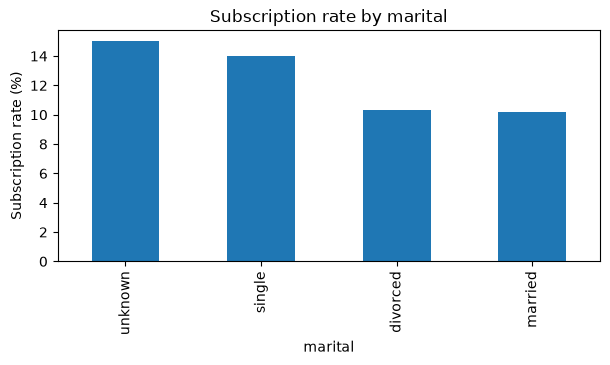

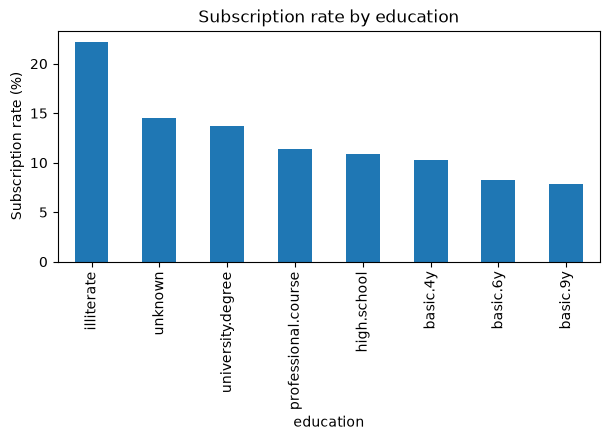

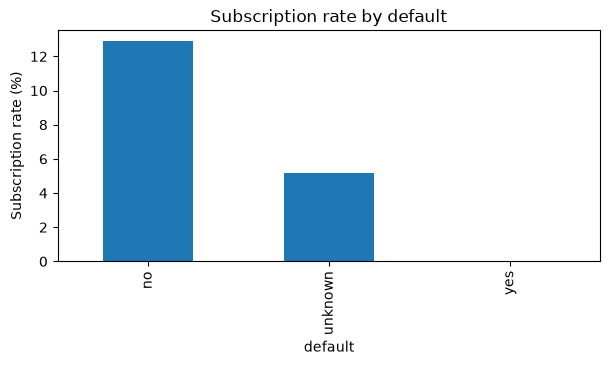

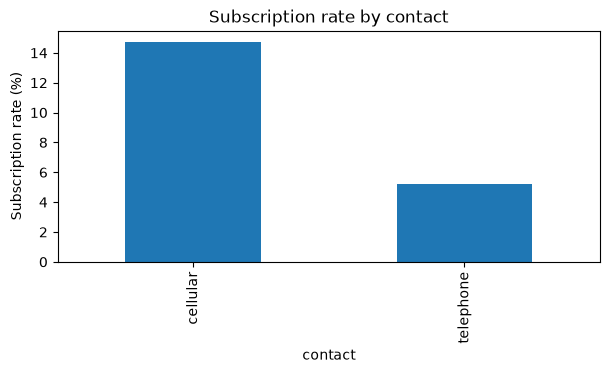

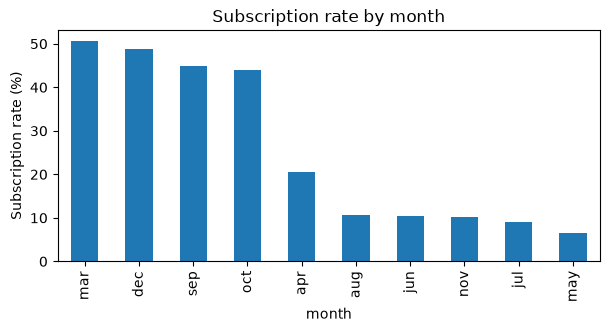

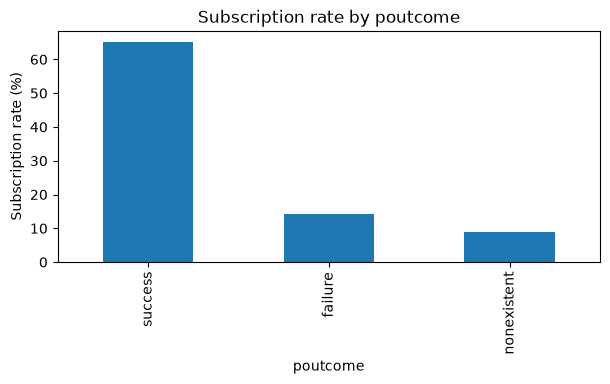

In [12]:
for col in ["marital", "education", "default", "contact", "month", "poutcome"]:
    rate = df.groupby(col)["y"].mean().sort_values(ascending=False) * 100
    rate.plot(kind="bar", figsize=(7, 3))
    plt.ylabel("Subscription rate (%)")
    plt.title(f"Subscription rate by {col}")
    plt.show()

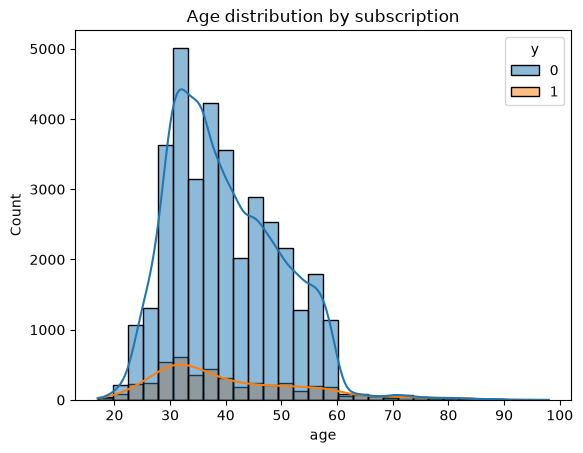

In [13]:
sns.histplot(data=df,x="age",hue="y",bins=30,kde=True)
plt.title("Age distribution by subscription")
plt.show()

In [14]:
print(df["pdays"].value_counts())

pdays
999    39673
3        439
6        412
4        118
9         64
2         61
7         60
12        58
10        52
5         46
13        36
11        28
1         26
15        24
14        20
8         18
0         15
16        11
17         8
18         7
22         3
19         3
21         2
25         1
26         1
27         1
20         1
Name: count, dtype: int64


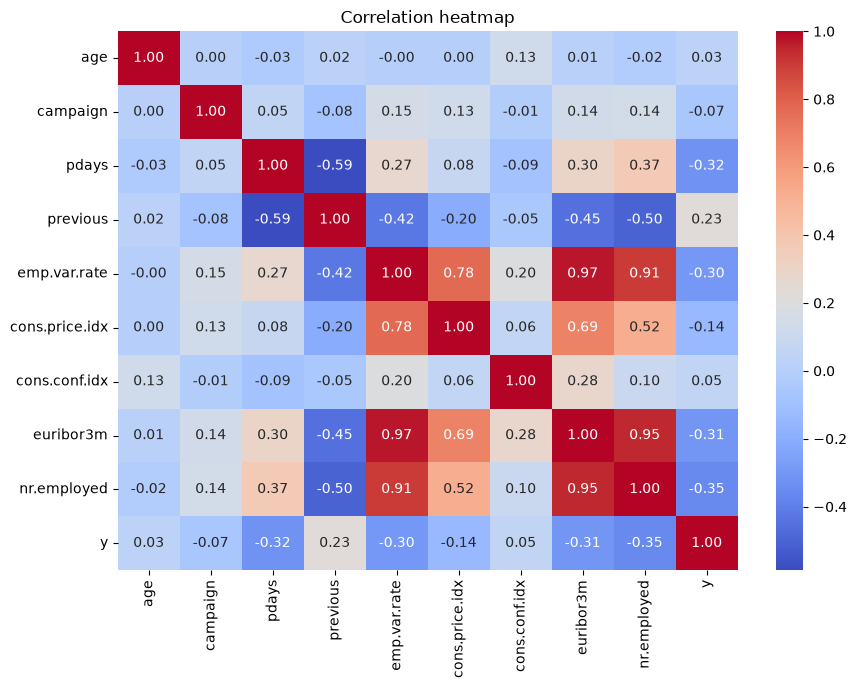

In [15]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes(include="number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

In [16]:
for col in ["month", "default", "poutcome", "contact"]:
    summary = df.groupby(col)["y"].agg(["count", "mean"])
    summary["mean"] = (summary["mean"] * 100).round(1)
    summary.columns = ["clients", "subscription_rate_%"]
    print(summary.sort_values("clients", ascending=False), "\n")

       clients  subscription_rate_%
month                              
may      13769                  6.4
jul       7174                  9.0
aug       6178                 10.6
jun       5318                 10.5
nov       4101                 10.1
apr       2632                 20.5
oct        718                 43.9
sep        570                 44.9
mar        546                 50.5
dec        182                 48.9 

         clients  subscription_rate_%
default                              
no         32588                 12.9
unknown     8597                  5.2
yes            3                  0.0 

             clients  subscription_rate_%
poutcome                                 
nonexistent    35563                  8.8
failure         4252                 14.2
success         1373                 65.1 

           clients  subscription_rate_%
contact                                
cellular     26144                 14.7
telephone    15044                  5.2 



### Feature Fixing

In [17]:
df["previously_contacted"] = (df["pdays"] != 999).astype(int)
df["pdays"] = df["pdays"].replace(999,0)

### Split and Preprocessing

In [18]:
X = df.drop(columns = "y")
y = df["y"]

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(32950, 20) (8238, 20)
0.11265553869499241 0.11264870114105366


In [20]:
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=["int64", "float64"]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [21]:
print("Numeric:", num_cols)
print("Caegorial:", cat_cols)

Numeric: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted']
Caegorial: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


### Baseline model with and without balanced version

In [22]:
baseline = Pipeline([
    ("prep" , preprocessor),
    ("model" , LogisticRegression(max_iter = 1000 , random_state = 42)),
])
baseline.fit(X_train,y_train)
    

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['age','job','marital',...,'euribor3m','nr.employed', 'previously_contacted']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [23]:
y_pred = baseline.predict(X_test)
y_prob = baseline.predict_proba(X_test)[:,1]
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

              precision    recall  f1-score   support

           0       0.91      0.99      0.95      7310
           1       0.69      0.22      0.33       928

    accuracy                           0.90      8238
   macro avg       0.80      0.60      0.64      8238
weighted avg       0.88      0.90      0.88      8238

[[7218   92]
 [ 725  203]]
ROC-AUC: 0.8008098111939241


In [24]:
baseline_bal = Pipeline([
    ("prep" , preprocessor),
    ("model" , LogisticRegression(max_iter = 1000,class_weight = "balanced" , random_state = 42)),
])
baseline_bal.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['age','job','marital',...,'euribor3m','nr.employed', 'previously_contacted']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all re

In [25]:
y_pred_bal = baseline_bal.predict(X_test)
y_prob_bal = baseline_bal.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_bal))
print(confusion_matrix(y_test, y_pred_bal))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_bal))
    

              precision    recall  f1-score   support

           0       0.95      0.86      0.90      7310
           1       0.37      0.65      0.47       928

    accuracy                           0.84      8238
   macro avg       0.66      0.75      0.69      8238
weighted avg       0.88      0.84      0.85      8238

[[6283 1027]
 [ 329  599]]
ROC-AUC: 0.8009504428274918


In [26]:
print(y_test)

14455    0
36380    0
40076    0
10778    0
27939    0
        ..
33359    1
34998    0
39861    0
3920     0
33395    0
Name: y, Length: 8238, dtype: int64


In [27]:
print(baseline.predict_proba(X_test)[:5])        # first 5 rows, both columns
print(baseline.predict_proba(X_test)[:5, 1])

[[0.93140382 0.06859618]
 [0.51801361 0.48198639]
 [0.43605308 0.56394692]
 [0.95552558 0.04447442]
 [0.58347005 0.41652995]]
[0.06859618 0.48198639 0.56394692 0.04447442 0.41652995]


### Training Different Models on the Dataset and Making Processing Pipelining 

In [28]:
processor_formultimodels = ColumnTransformer([
    ("num",StandardScaler(),num_cols),
    ("cat",OneHotEncoder(handle_unknown="ignore"),cat_cols),
])

In [29]:
results = []

def evaluate_model(name,model):
    start = time.time()
    pipe = Pipeline([
    ("prep", processor_formultimodels),
    ("model", model),
    ])
    pipe.fit(X_train,y_train)
    y_pred =  pipe.predict(X_test)
    if hasattr(pipe,"predict_proba"):
       score = pipe.predict_proba(X_test)[:,1]
    else:
       score = pipe.decision_function(X_test)
    
    results.append({
        "Model": name,
        "Recall (yes)": recall_score(y_test, y_pred),
        "Precision (yes)": precision_score(y_test, y_pred),
        "F1 (yes)": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, score),
        "Time (s)": time.time() - start,
    })

    return pipe

In [30]:
evaluate_model("Naive Bayes", GaussianNB())
evaluate_model("KNN", KNeighborsClassifier(n_neighbors=5))
evaluate_model("Decision Tree", DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42))
evaluate_model("Random Forest", RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=42, n_jobs=-1))
evaluate_model("logistic Regression", LogisticRegression(max_iter = 1000 , random_state=42))
evaluate_model("Balanced Logistic Regression" , LogisticRegression(max_iter = 1000 ,class_weight="balanced" ,random_state=42))
#evaluate_model("SVM", SVC(class_weight="balanced", random_state=42))
evaluate_model("Adaboost", AdaBoostClassifier(n_estimators = 200 , random_state = 42)),
evaluate_model("LightGBM", LGBMClassifier(n_esitmators = 300 , random_state = 42, learning_rate = 0.05 , class_weight="balanced", verbose = -1)),
result_df = pd.DataFrame(results).drop_duplicates(subset = "Model",keep = "last").sort_values("ROC-AUC", ascending=False).round(3)
result_df

,Model,Recall (yes),Precision (yes),F1 (yes),ROC-AUC,Time (s)
7,LightGBM,0.652,0.402,0.497,0.815,1.065
3,Random Forest,0.638,0.414,0.502,0.814,2.493
5,Balanced Logistic Regression,0.645,0.368,0.469,0.801,0.943
4,logistic Regression,0.219,0.688,0.332,0.801,0.711
6,Adaboost,0.205,0.714,0.318,0.800,19.003
2,Decision Tree,0.614,0.414,0.495,0.792,0.505
0,Naive Bayes,0.597,0.337,0.431,0.776,0.529
1,KNN,0.306,0.590,0.403,0.745,10.959


### Saving the result 

### Training Tuned Random Forest model on dataset

In [31]:
rf_pipeline = Pipeline([
    ("prep" , processor_formultimodels),
    ("model", RandomForestClassifier(class_weight="balanced",random_state=42,n_jobs=-1)),
     ])

rf_grid = {
    "model__n_estimators" : [200,400],
    "model__max_depth" : [6,10,14],
    "model__min_samples_leaf" : [5,10,20],
}

cv = StratifiedKFold(n_splits=5 , shuffle=True , random_state=42)

rf_search = GridSearchCV(rf_pipeline , rf_grid , scoring = "roc_auc" , n_jobs=2 , cv = cv , verbose=1)
rf_search.fit(X_train,y_train)
print("Best Settings :" , rf_search.best_params_)
print(" Best cv roc_auc:" , round(rf_search.best_score_ ,4))

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best Settings : {'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
 Best cv roc_auc: 0.7964


In [32]:
rf_best = rf_search.best_estimator_
y_pred = rf_best.predict(X_test)
y_porba = rf_best.predict_proba(X_test)[:,1]

print(classification_report(y_test,y_pred)),
print(confusion_matrix(y_test,y_pred)),
print("roc_auc score:" , roc_auc_score(y_test,y_prob)),

              precision    recall  f1-score   support

           0       0.95      0.88      0.91      7310
           1       0.40      0.64      0.50       928

    accuracy                           0.85      8238
   macro avg       0.68      0.76      0.71      8238
weighted avg       0.89      0.85      0.87      8238

[[6435  875]
 [ 333  595]]
roc_auc score: 0.8008098111939241


(None,)

In [33]:
print(y_train.mean(), y_test.mean())
print(X_train.shape, X_test.shape)

0.11265553869499241 0.11264870114105366
(32950, 20) (8238, 20)


In [34]:
rf_best = rf_search.best_estimator_

y_pred_rf = rf_best.predict(X_test)
y_prob_rf = rf_best.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))
print("Tuned RF ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

              precision    recall  f1-score   support

           0       0.95      0.88      0.91      7310
           1       0.40      0.64      0.50       928

    accuracy                           0.85      8238
   macro avg       0.68      0.76      0.71      8238
weighted avg       0.89      0.85      0.87      8238

[[6435  875]
 [ 333  595]]
Tuned RF ROC-AUC: 0.813129304448323


### Saving the Tuned Random Forest to the dataframe

In [35]:
results.append({
    "Model": "Random Forest (tuned)",
    "Recall (yes)": recall_score(y_test, y_pred_rf),
    "Precision (yes)": precision_score(y_test, y_pred_rf),
    "F1 (yes)": f1_score(y_test, y_pred_rf),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf),
    "Time (s)": None,
})
result_df = pd.DataFrame(results).drop_duplicates(subset = "Model",keep = "last").sort_values("ROC-AUC", ascending=False).round(3)
result_df

,Model,Recall (yes),Precision (yes),F1 (yes),ROC-AUC,Time (s)
7,LightGBM,0.652,0.402,0.497,0.815,1.065
3,Random Forest,0.638,0.414,0.502,0.814,2.493
8,Random Forest (tuned),0.641,0.405,0.496,0.813,NaN
5,Balanced Logistic Regression,0.645,0.368,0.469,0.801,0.943
4,logistic Regression,0.219,0.688,0.332,0.801,0.711
6,Adaboost,0.205,0.714,0.318,0.800,19.003
2,Decision Tree,0.614,0.414,0.495,0.792,0.505
0,Naive Bayes,0.597,0.337,0.431,0.776,0.529
1,KNN,0.306,0.590,0.403,0.745,10.959


### Tuned Light Gradient Base Classifier

In [36]:
lgbm_pipe = Pipeline([
     ("prep" , processor_formultimodels),
    ("model", LGBMClassifier(class_weight="balanced",random_state=42,verbose=-1)),
])
lgbm_grid = {
     "model__n_estimators": [200, 400],
    "model__learning_rate": [0.03, 0.05],
    "model__num_leaves": [15, 31],
    "model__min_child_samples": [20, 50],
}

cv =  StratifiedKFold(n_splits = 5 , shuffle = True, random_state=42)
lgbm_search = GridSearchCV(lgbm_pipe, lgbm_grid, scoring="roc_auc", cv=cv, n_jobs=1, verbose=1)
lgbm_search.fit(X_train,y_train)
print("Best settings:", lgbm_search.best_params_)
print("Best CV ROC-AUC:", round(lgbm_search.best_score_, 4))

lgbm_best = lgbm_search.best_estimator_

y_pred_lgbm = lgbm_best.predict(X_test)
y_prob_lgbm = lgbm_best.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_lgbm))
print(confusion_matrix(y_test, y_pred_lgbm))
print("Tuned LightGBM ROC-AUC:", roc_auc_score(y_test, y_prob_lgbm))


results.append({
    "Model": "LightGBM (tuned)",
    "Recall (yes)": recall_score(y_test, y_pred_lgbm),
    "Precision (yes)": precision_score(y_test, y_pred_lgbm),
    "F1 (yes)": f1_score(y_test, y_pred_lgbm),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lgbm),
    "Time (s)": None,
})

results_df = (
    pd.DataFrame(results)
    .drop_duplicates(subset="Model", keep="last")
    .sort_values("ROC-AUC", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

results_df.to_csv("model_comparison.csv", index=False)
results_df

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best settings: {'model__learning_rate': 0.03, 'model__min_child_samples': 20, 'model__n_estimators': 200, 'model__num_leaves': 15}
Best CV ROC-AUC: 0.7984
              precision    recall  f1-score   support

           0       0.95      0.87      0.91      7310
           1       0.39      0.66      0.49       928

    accuracy                           0.85      8238
   macro avg       0.67      0.77      0.70      8238
weighted avg       0.89      0.85      0.86      8238

[[6369  941]
 [ 316  612]]
Tuned LightGBM ROC-AUC: 0.8160137270625973


,Model,Recall (yes),Precision (yes),F1 (yes),ROC-AUC,Time (s)
0,LightGBM (tuned),0.659,0.394,0.493,0.816,NaN
1,LightGBM,0.652,0.402,0.497,0.815,1.065
2,Random Forest,0.638,0.414,0.502,0.814,2.493
3,Random Forest (tuned),0.641,0.405,0.496,0.813,NaN
4,Balanced Logistic Regression,0.645,0.368,0.469,0.801,0.943
5,logistic Regression,0.219,0.688,0.332,0.801,0.711
6,Adaboost,0.205,0.714,0.318,0.800,19.003
7,Decision Tree,0.614,0.414,0.495,0.792,0.505
8,Naive Bayes,0.597,0.337,0.431,0.776,0.529
9,KNN,0.306,0.590,0.403,0.745,10.959


In [37]:
result_df.to_csv("model_comparison.csv", index=False)

In [38]:
train_prob = cross_val_predict(
    lgbm_best , X_train, y_train, cv=cv, method="predict_proba")[:,1]


### Treshold Tuning on LGBM

In [39]:
rows = []
for t in np.arange(0.10, 0.91, 0.05):
    pred = (train_prob >= t).astype(int)
    rows.append({
        "Threshold": round(t, 2),
        "Recall": recall_score(y_train, pred),
        "Precision": precision_score(y_train, pred, zero_division=0),
        "F1": f1_score(y_train, pred),
        "Clients called": int(pred.sum()),
    })

thr_table = pd.DataFrame(rows).round(3)
thr_table

,Threshold,Recall,Precision,F1,Clients called
0,0.10,0.997,0.113,0.203,32694
1,0.15,0.991,0.115,0.205,32097
2,0.20,0.964,0.126,0.222,28501
3,0.25,0.920,0.143,0.247,23896
4,0.30,0.850,0.173,0.287,18297
5,0.35,0.760,0.220,0.342,12812
6,0.40,0.690,0.287,0.406,8916
7,0.45,0.657,0.337,0.445,7251
8,0.50,0.628,0.370,0.466,6292
9,0.55,0.603,0.408,0.487,5483


In [40]:
value_per_sale = 10   # assumption: one subscription is worth 10 calls
cost_per_call = 1

thr_table["Profit"] = (thr_table["Recall"] * y_train.sum() * value_per_sale
                       - thr_table["Clients called"] * cost_per_call)

thr_table.sort_values("Profit", ascending=False).head(5)

,Threshold,Recall,Precision,F1,Clients called,Profit
7,0.45,0.657,0.337,0.445,7251,17136.84
8,0.50,0.628,0.370,0.466,6292,17019.36
9,0.55,0.603,0.408,0.487,5483,16900.36
6,0.40,0.690,0.287,0.406,8916,16696.80
10,0.60,0.584,0.430,0.495,5039,16639.08


In [41]:
best_t = 0.45   # replace with your chosen cutoff

test_pred = (y_prob_lgbm >= best_t).astype(int)

print(classification_report(y_test, test_pred))
print(confusion_matrix(y_test, test_pred))

              precision    recall  f1-score   support

           0       0.95      0.84      0.89      7310
           1       0.35      0.68      0.47       928

    accuracy                           0.82      8238
   macro avg       0.65      0.76      0.68      8238
weighted avg       0.89      0.82      0.85      8238

[[6158 1152]
 [ 294  634]]


### Feature Selection

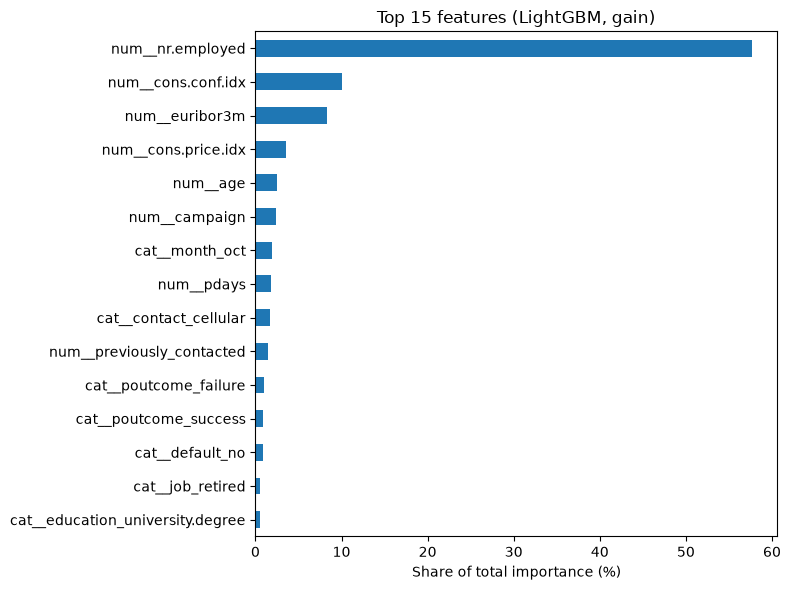

In [42]:
model = lgbm_best.named_steps["model"]
names = lgbm_best.named_steps["prep"].get_feature_names_out()
gain = model.booster_.feature_importance(importance_type = "gain")
imp = pd.Series(gain, index=names)
imp = (imp/imp.sum() *100).sort_values(ascending = False)
imp.head(15).iloc[::-1].plot(kind="barh", figsize=(8, 6))
plt.xlabel("Share of total importance (%)")
plt.title("Top 15 features (LightGBM, gain)")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [43]:
from sklearn.model_selection import cross_val_score

econ_all = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
econ_redundant = ["emp.var.rate", "euribor3m"]   

best_params = {k.replace("model__", ""): v for k, v in lgbm_search.best_params_.items()}

def run_experiment(label, drop_cols):
    Xtr = X_train.drop(columns=drop_cols)
    Xte = X_test.drop(columns=drop_cols)

    nc = Xtr.select_dtypes(include="number").columns.tolist()
    cc = Xtr.select_dtypes(exclude="number").columns.tolist()

    prep = ColumnTransformer([
        ("num", StandardScaler(), nc),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cc),
    ])

    pipe = Pipeline([
        ("prep", prep),
        ("model", LGBMClassifier(class_weight="balanced", random_state=42, verbose=-1, **best_params)),
    ])

    cv_auc = cross_val_score(pipe, Xtr, y_train, cv=cv, scoring="roc_auc").mean()
    pipe.fit(Xtr, y_train)
    test_auc = roc_auc_score(y_test, pipe.predict_proba(Xte)[:, 1])

    return {"Features used": label, "Columns": Xtr.shape[1],
            "CV ROC-AUC": round(cv_auc, 4), "Test ROC-AUC": round(test_auc, 4)}

fs_results = [
    run_experiment("All features", []),
    run_experiment("Without emp.var.rate and euribor3m", econ_redundant),
    run_experiment("Without all economic columns", econ_all),
]

pd.DataFrame(fs_results)

,Features used,Columns,CV ROC-AUC,Test ROC-AUC
0,All features,20,0.7984,0.8160
1,Without emp.var.rate and euribor3m,18,0.7922,0.8081
2,Without all economic columns,15,0.7717,0.7833


### Saving the final model

In [44]:
joblib.dump(lgbm_best, "final_model.joblib")
joblib.dump({"threshold": 0.45, "columns": X_train.columns.tolist()}, "model_info.joblib")

['model_info.joblib']

In [45]:
loaded = joblib.load("final_model.joblib")
print(roc_auc_score(y_test, loaded.predict_proba(X_test)[:, 1]))

0.8160137270625973


In [46]:
results_df["Model"] = results_df["Model"].replace({
    "logistic Regression": "Logistic Regression",
    "Balanced Logistic Regression": "Logistic Regression (balanced)",
    "Adaboost": "AdaBoost",
})
results_df.to_csv("model_comparison.csv", index=False)
results_df

,Model,Recall (yes),Precision (yes),F1 (yes),ROC-AUC,Time (s)
0,LightGBM (tuned),0.659,0.394,0.493,0.816,NaN
1,LightGBM,0.652,0.402,0.497,0.815,1.065
2,Random Forest,0.638,0.414,0.502,0.814,2.493
3,Random Forest (tuned),0.641,0.405,0.496,0.813,NaN
4,Logistic Regression (balanced),0.645,0.368,0.469,0.801,0.943
5,Logistic Regression,0.219,0.688,0.332,0.801,0.711
6,AdaBoost,0.205,0.714,0.318,0.800,19.003
7,Decision Tree,0.614,0.414,0.495,0.792,0.505
8,Naive Bayes,0.597,0.337,0.431,0.776,0.529
9,KNN,0.306,0.590,0.403,0.745,10.959
